# Section 1: Data Forensics — Analysis Code

Dataset: hotel_bookings.csv

### Setup

In [1]:
import pandas as pd
import numpy as np


df = pd.read_csv('hotel_bookings.csv', keep_default_na=False)

print(f"Shape: {df.shape}")
print(f"Duplicate booking_id rows: {df['booking_id'].duplicated().sum()}")
df.sample(3)

Shape: (12000, 28)
Duplicate booking_id rows: 0


,booking_id,customer_id,customer_name,customer_segment,customer_signup_date,customer_home_city,customer_loyalty_tier,property_id,property_name,property_city,...,nights,booking_channel,adr,discount_amount,coupon_code,total_amount,payment_method,booking_status,review_rating,review_date
10651,110651,4880,Customer_4880,Individual,2022-01-02,Manali,None,45,Velvet Heights,Jaipur,...,2,OTA,3565.80,0.0,,7131.60,Net Banking,Cancelled,,
2993,102993,1379,Customer_1379,Corporate,2023-06-22,Jaipur,None,28,Ivory Manor,Mumbai,...,4,Direct Website,5211.53,0.0,NONE,41692.24,Net Banking,Completed,7.0,2024-02-16
9330,109330,4253,Customer_4253,Corporate,2022-04-19,Udaipur,Silver,13,Marigold Lodge,Kochi,...,1,Corporate Portal,4339.30,0.0,,13017.90,Net Banking,Completed,5.0,2024-05-16


In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12000 entries, 0 to 11999
Data columns (total 28 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   booking_id             12000 non-null  int64  
 1   customer_id            12000 non-null  int64  
 2   customer_name          12000 non-null  object 
 3   customer_segment       12000 non-null  object 
 4   customer_signup_date   12000 non-null  object 
 5   customer_home_city     12000 non-null  object 
 6   customer_loyalty_tier  12000 non-null  object 
 7   property_id            12000 non-null  int64  
 8   property_name          12000 non-null  object 
 9   property_city          12000 non-null  object 
 10  property_star_rating   12000 non-null  int64  
 11  property_type          12000 non-null  object 
 12  property_total_rooms   12000 non-null  int64  
 13  booking_date           12000 non-null  object 
 14  checkin_date           12000 non-null  object 
 15  ch

---
## DQ1 — num_rooms = 0

In [3]:
zero_room_count = (df['num_rooms'] == 0).sum()
pct = zero_room_count / len(df) * 100

zero_room_amount_check = df.loc[df['num_rooms'] == 0, 'total_amount'].eq(0).all()

print(f"Bookings with num_rooms = 0: {zero_room_count} ({pct:.2f}% of all bookings)")
print(f"All of these carry total_amount = 0: {zero_room_amount_check}")

Bookings with num_rooms = 0: 60 (0.50% of all bookings)
All of these carry total_amount = 0: True


---
## DQ2 — booking_date earlier than customer_signup_date

In [4]:
df['booking_date'] = pd.to_datetime(df['booking_date'])
df['customer_signup_date'] = pd.to_datetime(df['customer_signup_date'])

early_booking_count = (df['booking_date'] < df['customer_signup_date']).sum()
pct = early_booking_count / len(df) * 100

print(f"Bookings before signup date: {early_booking_count} ({pct:.2f}% of all bookings)")

Bookings before signup date: 364 (3.03% of all bookings)


---
## DQ3 — bookings with no review, by booking_status

In [5]:

no_review = df['review_rating'].astype(str).str.strip().eq('')

overall_pct = no_review.mean() * 100
by_status_pct = no_review.groupby(df['booking_status']).mean().mul(100).round(2)
counts_by_status = df['booking_status'].value_counts()

print(f"Overall % of bookings with no review: {overall_pct:.2f}%\n")
print("By booking_status:")
print(by_status_pct)
print("\nStatus volumes (for context):")
print(counts_by_status)

Overall % of bookings with no review: 57.70%

By booking_status:
booking_status
Cancelled     97.88
Completed     45.83
No-Show      100.00
Name: review_rating, dtype: float64

Status volumes (for context):
booking_status
Completed    9279
Cancelled    2360
No-Show       361
Name: count, dtype: int64


---
## DQ4 — undocumented issue discovery (total_amount formula check)

In [6]:

expected_total = df['adr'] * df['num_rooms'] * df['nights'] - df['discount_amount']
diff = (df['total_amount'] - expected_total).abs()

mismatch_mask = diff > 1  
mismatch_count = mismatch_mask.sum()
mismatch_pct = mismatch_count / len(df) * 100

print(f"Rows where stored total_amount contradicts the stated formula: {mismatch_count} ({mismatch_pct:.2f}%)\n")
print("Breakdown by booking_status:")
print(df.loc[mismatch_mask, 'booking_status'].value_counts())
print("\nSample mismatched rows:")
df.loc[mismatch_mask, ['booking_id', 'adr', 'num_rooms', 'nights', 'discount_amount', 'total_amount']].assign(
    expected_total_amount=lambda d: (d['adr'] * d['num_rooms'] * d['nights'] - d['discount_amount']).round(2)
).head(8)

Rows where stored total_amount contradicts the stated formula: 35 (0.29%)

Breakdown by booking_status:
booking_status
Completed    26
Cancelled     9
Name: count, dtype: int64

Sample mismatched rows:


,booking_id,adr,num_rooms,nights,discount_amount,total_amount,expected_total_amount
16,100016,3349.28,1,4,0.00,12057.41,13397.12
545,100545,13704.54,1,2,4059.38,19290.32,23349.70
579,100579,6687.12,1,1,1338.00,6687.12,5349.12
686,100686,10825.58,1,2,4431.74,12787.68,17219.42
1221,101221,5295.95,1,2,0.00,9532.71,10591.90
1428,101428,3819.41,3,2,0.00,15277.64,22916.46
1601,101601,2557.64,1,3,0.00,6905.63,7672.92
1927,101927,5986.15,1,3,0.00,16162.60,17958.45


---
# Section 2: VIP-vs-Volume Case Study — Analysis Code

## CS1 — Define VIP Three Ways

In [7]:
completed = df[df['booking_status'] == 'Completed'].copy()

# Reference "today" = latest booking_date in the dataset, so LTV rate is reproducible
ref_date = df['booking_date'].max()

agg = completed.groupby('customer_id').agg(
    total_spend=('total_amount', 'sum'),
    booking_count=('booking_id', 'count'),
    signup_date=('customer_signup_date', 'first')
).reset_index()

print(f"Customers with >=1 completed booking: {len(agg)}")
agg.head()

Customers with >=1 completed booking: 4719


,customer_id,total_spend,booking_count,signup_date
0,1,145639.44,4,2023-12-26
1,2,3732.13,1,2022-07-25
2,3,14079.22,1,2023-05-01
3,4,6550.30,1,2023-02-25
4,5,58049.98,3,2023-06-20


In [8]:
# LTV rate = total spend / months since signup (spend velocity, not raw total).
# clip(lower=1) prevents a very recent signup from producing an artificially
# inflated rate by dividing by a near-zero number of months.
agg['months_since_signup'] = (
    (ref_date - agg['signup_date']).dt.days / 30.44
).clip(lower=1)
agg['ltv_rate'] = agg['total_spend'] / agg['months_since_signup']

n = len(agg)
top10_n = int(np.ceil(n * 0.10))
print(f"Total customers: {n}  |  Top 10% cutoff: {top10_n} customers per definition")

Total customers: 4719  |  Top 10% cutoff: 472 customers per definition


In [9]:
set_spend = set(agg.nlargest(top10_n, 'total_spend')['customer_id'])
set_count = set(agg.nlargest(top10_n, 'booking_count')['customer_id'])
set_ltv   = set(agg.nlargest(top10_n, 'ltv_rate')['customer_id'])

all3        = set_spend & set_count & set_ltv
spend_count = (set_spend & set_count) - set_ltv
spend_ltv   = (set_spend & set_ltv) - set_count
count_ltv   = (set_count & set_ltv) - set_spend
only_spend  = set_spend - set_count - set_ltv
only_count  = set_count - set_spend - set_ltv
only_ltv    = set_ltv - set_spend - set_count

union_size = len(set_spend | set_count | set_ltv)

print(f"All three definitions:  {len(all3)}")
print(f"Exactly two definitions: {len(spend_count) + len(spend_ltv) + len(count_ltv)}")
print(f"  spend & count only:  {len(spend_count)}")
print(f"  spend & ltv only:    {len(spend_ltv)}")
print(f"  count & ltv only:    {len(count_ltv)}")
print(f"Only one definition:    {len(only_spend) + len(only_count) + len(only_ltv)}")
print(f"  spend only: {len(only_spend)}  |  count only: {len(only_count)}  |  ltv only: {len(only_ltv)}")
print(f"Union (any definition): {union_size}")

All three definitions:  208
Exactly two definitions: 239
  spend & count only:  44
  spend & ltv only:    154
  count & ltv only:    41
Only one definition:    314
  spend only: 66  |  count only: 179  |  ltv only: 69
Union (any definition): 761


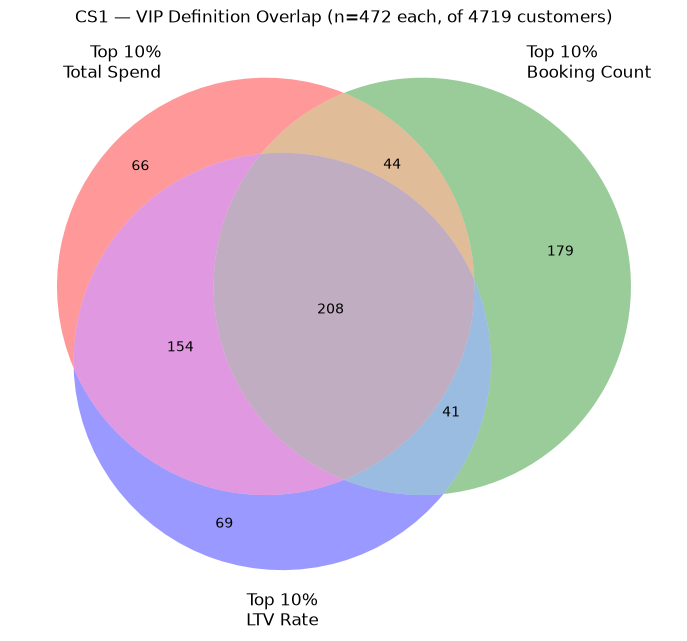

In [10]:
import matplotlib.pyplot as plt
from matplotlib_venn import venn3

fig, ax = plt.subplots(figsize=(7, 7))
venn3(
    [set_spend, set_count, set_ltv],
    set_labels=('Top 10%\nTotal Spend', 'Top 10%\nBooking Count', 'Top 10%\nLTV Rate'),
    ax=ax
)
plt.title(f"CS1 — VIP Definition Overlap (n={top10_n} each, of {n} customers)")
plt.tight_layout()
plt.show()

## CS2 — VIP Risk Profile

In [11]:
vip_ids = set_spend  # from CS1 — top 10% by total_spend
df['is_vip'] = df['customer_id'].isin(vip_ids)

print(f"VIP customers: {len(vip_ids)} of {df['customer_id'].nunique()} total customers")
print(f"VIP bookings (all statuses): {df['is_vip'].sum()} of {len(df)}")

VIP customers: 472 of 5464 total customers
VIP bookings (all statuses): 3037 of 12000


### (a) Revenue share

In [12]:
realized = df[df['booking_status'] == 'Completed']
total_realized = realized['total_amount'].sum()

vip_realized = realized.loc[realized['is_vip'], 'total_amount'].sum()
vip_revenue_share = vip_realized / total_realized * 100

print(f"Total realized revenue: Rs {total_realized:,.0f}")
print(f"VIP realized revenue:   Rs {vip_realized:,.0f}  ({vip_revenue_share:.1f}% of total)")

Total realized revenue: Rs 276,525,707
VIP realized revenue:   Rs 121,961,170  (44.1% of total)


### (b) Cancellation rate

In [13]:
vip_b, nonvip_b = df[df['is_vip']], df[~df['is_vip']]

vip_cancel_rate = (vip_b['booking_status'] == 'Cancelled').mean() * 100
nonvip_cancel_rate = (nonvip_b['booking_status'] == 'Cancelled').mean() * 100

print(f"VIP cancellation rate:     {vip_cancel_rate:.1f}%")
print(f"Non-VIP cancellation rate: {nonvip_cancel_rate:.1f}%")

VIP cancellation rate:     15.4%
Non-VIP cancellation rate: 21.1%


### (c) Discount intensity

In [14]:
vip_avg_discount = vip_b['discount_amount'].mean()
nonvip_avg_discount = nonvip_b['discount_amount'].mean()

print(f"VIP avg discount/booking:     Rs {vip_avg_discount:.0f}")
print(f"Non-VIP avg discount/booking: Rs {nonvip_avg_discount:.0f}")

VIP avg discount/booking:     Rs 2684
Non-VIP avg discount/booking: Rs 1390


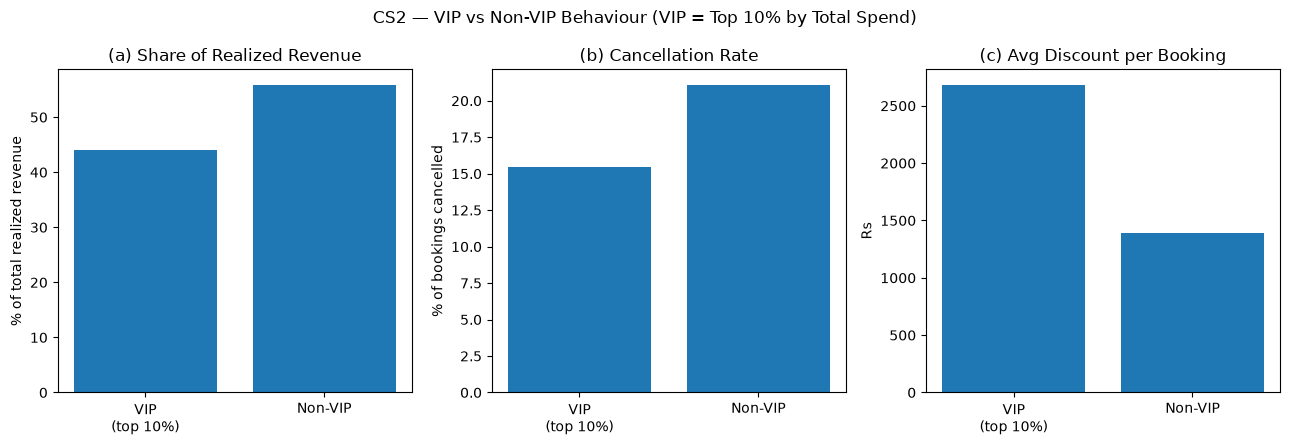

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.5))
labels = ['VIP\n(top 10%)', 'Non-VIP']

axes[0].bar(labels, [vip_revenue_share, 100 - vip_revenue_share])
axes[0].set_title('(a) Share of Realized Revenue')
axes[0].set_ylabel('% of total realized revenue')

axes[1].bar(labels, [vip_cancel_rate, nonvip_cancel_rate])
axes[1].set_title('(b) Cancellation Rate')
axes[1].set_ylabel('% of bookings cancelled')

axes[2].bar(labels, [vip_avg_discount, nonvip_avg_discount])
axes[2].set_title('(c) Avg Discount per Booking')
axes[2].set_ylabel('Rs')

plt.suptitle('CS2 — VIP vs Non-VIP Behaviour (VIP = Top 10% by Total Spend)')
plt.tight_layout()
plt.show()

## CS3 — Acquisition vs Retention Math

### (a) Acquisition

In [ ]:
budget = 5000000 
cac = 3000          

new_customers = budget / cac
avg_lifetime_spend = agg['total_spend'].mean()
year1_revenue_acq = new_customers * avg_lifetime_spend * 0.20 

print(f"New customers acquirable: {new_customers:.0f}")
print(f"Avg customer lifetime spend: Rs {avg_lifetime_spend:,.0f}")
print(f"Year-1 revenue from acquisition spend: Rs {year1_revenue_acq:,.0f}")
print(f"Year-1 ROI multiple: {year1_revenue_acq/budget:.2f}x")

New customers acquirable: 1667
Avg customer lifetime spend: Rs 58,598
Year-1 revenue from acquisition spend: Rs 19,532,790
Year-1 ROI multiple: 3.91x


### (b) Retention

In [ ]:
retention_cost = 500 

retainable = budget / retention_cost
total_customers = df['customer_id'].nunique()
vip_pool = len(vip_ids)

print(f"Theoretically retainable customers: {retainable:.0f}")
print(f"Actual total customers in the dataset: {total_customers}")
print(f"Actual VIP (at-risk, high-value) pool: {vip_pool}")
print(f"Retainable as % of total customer base: {retainable/total_customers*100:.0f}%")
print(f"Retainable as a multiple of the actual VIP pool: {retainable/vip_pool:.1f}x")

Theoretically retainable customers: 10000
Actual total customers in the dataset: 5464
Actual VIP (at-risk, high-value) pool: 472
Retainable as % of total customer base: 183%
Retainable as a multiple of the actual VIP pool: 21.2x


## CS4 — Recommendation + Leading Indicator

In [18]:
vip_pool = len(vip_ids)
retention_budget = vip_pool * retention_cost          # cover every VIP at Rs 500/year
acquisition_budget = budget - retention_budget

new_customers_final = acquisition_budget / cac
year1_revenue_final = new_customers_final * avg_lifetime_spend * 0.20

vip_revenue_at_stake = vip_realized

print(f"Retention budget:    Rs {retention_budget:,}  ({retention_budget/budget*100:.1f}% of Rs 50L)")
print(f"Acquisition budget:  Rs {acquisition_budget:,}  ({acquisition_budget/budget*100:.1f}% of Rs 50L)")
print(f"New customers acquired: {new_customers_final:.0f}")
print(f"Year-1 revenue from acquisition: Rs {year1_revenue_final:,.0f}")
print(f"VIP realized revenue protected by retention: Rs {vip_revenue_at_stake:,.0f}")
print(f"Retention budget as % of VIP revenue at stake: {retention_budget/vip_revenue_at_stake*100:.3f}%")

Retention budget:    Rs 236,000  (4.7% of Rs 50L)
Acquisition budget:  Rs 4,764,000  (95.3% of Rs 50L)
New customers acquired: 1588
Year-1 revenue from acquisition: Rs 18,610,842
VIP realized revenue protected by retention: Rs 121,961,170
Retention budget as % of VIP revenue at stake: 0.194%


---
# Section 3: SQL Challenge — Schema + Query Verification

## Schema (see schema.sql for the full standalone file)

```sql
CREATE TABLE customers ( ... );
CREATE TABLE properties ( ... );
CREATE TABLE bookings ( ... );
CREATE TABLE reviews ( ... );
CREATE INDEX idx_bookings_customer_checkin ON bookings (customer_id, checkin_date);
```


In [19]:
import sqlite3

con = sqlite3.connect(':memory:')
df.to_sql('bookings_flat', con, index=False, if_exists='replace')
print("Loaded", pd.read_sql("SELECT COUNT(*) AS n FROM bookings_flat", con)['n'][0], "rows into SQLite")

Loaded 12000 rows into SQLite


## C-Q1 — Average total_amount by booking sequence

In [20]:
q1 = """
WITH numbered AS (
    SELECT
        customer_id,
        total_amount,
        ROW_NUMBER() OVER (PARTITION BY customer_id ORDER BY checkin_date) AS seq
    FROM bookings_flat
    WHERE booking_status = 'Completed'
),
labeled AS (
    SELECT
        CASE
            WHEN seq = 1 THEN 'first'
            WHEN seq = 2 THEN 'second'
            ELSE '3-or-later'
        END AS sequence_label,
        total_amount
    FROM numbered
)
SELECT
    sequence_label,
    ROUND(AVG(total_amount), 2) AS avg_total,
    COUNT(*) AS n
FROM labeled
GROUP BY sequence_label
ORDER BY CASE sequence_label
    WHEN 'first' THEN 1 WHEN 'second' THEN 2 ELSE 3 END;
"""

result_q1 = pd.read_sql(q1, con)
result_q1

,sequence_label,avg_total,n
0,first,29765.24,4719
1,second,29328.32,1884
2,3-or-later,30197.68,2676


## C-Q2 — Top 5 properties by normalized average review rating

In [21]:
q2 = """
WITH normalized_reviews AS (
    SELECT
        property_id,
        CASE
            WHEN customer_segment = 'Corporate' THEN CAST(review_rating AS FLOAT) / 2.0
            ELSE CAST(review_rating AS FLOAT)
        END AS normalized_rating
    FROM bookings_flat
    WHERE TRIM(review_rating) <> ''
)
SELECT
    bf.property_name,
    bf.property_city,
    COUNT(*) AS num_reviews,
    ROUND(AVG(nr.normalized_rating), 2) AS normalized_avg_rating
FROM normalized_reviews nr
JOIN (SELECT DISTINCT property_id, property_name, property_city FROM bookings_flat) bf
    ON bf.property_id = nr.property_id
GROUP BY bf.property_id, bf.property_name, bf.property_city
HAVING COUNT(*) >= 20
ORDER BY normalized_avg_rating DESC
LIMIT 5;
"""

result_q2 = pd.read_sql(q2, con)
result_q2

,property_name,property_city,num_reviews,normalized_avg_rating
0,Tusker Lodge,Mumbai,91,3.95
1,Banyan Heights,Mumbai,78,3.92
2,Crimson Residency,Chennai,97,3.92
3,Mango Manor,Jaipur,91,3.91
4,Pearl Retreat,Mumbai,76,3.89
